### 03b — Recombination status in a mosaic conditional knockout

This notebook exists because your experiment is
`Pdx1-CreER; Bola3 fl/fl` with tamoxifen induction and an 8-month chase — a
*mosaic* knockout — and the standard two-group design does not describe it.

### The problem with `genotype`---- 
A "KO mouse" contains recombined beta cells and escapers. Cre is beta-restricted,
so alpha, delta, ductal, endothelial and immune cells in that same mouse are
never recombined at all. `genotype` is a label on the **animal**, not on the cell.

Comparing all KO beta cells against all WT beta cells therefore compares a
*mixture* against a pure population. The measured effect is
`recombination_rate × true_effect`. At 65% efficiency a true log2FC of 1.0
reads as 0.65, and genes with modest true effects fall out of significance
entirely. You would be underpowered without knowing by how much.

### What mosaicism gives back--- Two internal control populations that a germline knockout would not have:

- **Escaper beta cells** — same mouse, same tamoxifen, same islet isolation,
  same circulating glucose, but no cell-autonomous lesion. Comparing recombined
  against escaper cells *within* an animal removes mouse-to-mouse variation
  entirely, which at n=4 is your dominant noise source.
- **Non-beta cells** — definitionally unrecombined. Any change there is
  non-cell-autonomous by construction.

This matters especially for you because your KO mice are glucose intolerant.
Chronic hyperglycaemia independently causes beta-cell dedifferentiation and
stress-response activation — the same signature Bola3 loss predicts. Escaper
cells experience the animal's glycaemia but not the lesion, so the
escaper-vs-recombined contrast is what separates the two.

### Two limits to state plainly---

**Survivor bias.** Over 8 months, the beta cells with the most complete Bola3
loss are the most likely to have died. The recombined cells you sequenced are
the ones that *tolerated* the lesion. Every effect size below is a lower bound.

**Recombination may not be random.** Pdx1-CreER fires in proportion to Pdx1
activity, so mature beta cells may be preferentially recombined. §3b.5 tests
this; it cannot be fully excluded without a lineage reporter.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
sys.path.insert(0, str(Path.cwd().parent / "resources"))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg
from recombination import (check_recombination_bias, classify, cutoff_sweep,
                           dilution_factor, feasibility_report)

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

adata = sc.read_h5ad(cfg.H5AD["annotated"])
PALETTE = {"WT": "#4C72B0", "escaper": "#8DA65B", "recombined": "#C44E52",
           "undetermined": "#cccccc"}
print(adata)

AnnData object with n_obs × n_vars = 78760 × 22679
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'total_counts_hormone', 'pct_counts_hormone', 'z_outlier', 'below_valley', 'doublet_score', 'predicted_doublet', 'qc_fail', 'qc_reason', 'leiden_fine', 'leiden', 'level_1', 'level_2', 'level_3', 'ins_gcg_double', 'cell_type', 'cell_type_coarse', 'beta_cluster', 'score_Beta_identity', 'score_Beta_disallowed', 'score_Beta_dedifferentiation', 'score_OXPHOS_all', 'score_Integrated_stress_response', 'beta_mature', 'beta_immature', 'beta_dediff'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_

### 3b.1 Can Bola3 reads report recombination at all?

**Run this before anything else.** Whether recombination reduces the Bola3
count depends on where the excised region sits relative to the read-capture
end. This dataset is **10x 5' (NextGEM v2, R2-only)**, so reads come from the
transcript's 5' end near the TSS — the opposite of 3' chemistry. That means a
5'-proximal / early-exon excision is the *best* case for detecting
recombination, while a purely 3' flox may leave the captured region intact.
Two things make this robust: a frameshift or premature stop usually triggers
nonsense-mediated decay and collapses the whole transcript regardless of read
position; and this test answers the question empirically either way, so no
assumption about flox position is load-bearing.

The logic uses Cre's beta-restriction as a built-in negative control:

- KO **non-beta** vs WT **non-beta** → should be **equal** (Cre never fired)
- KO **beta** vs WT **beta** → should be **lower**, by roughly the
  recombination efficiency
Pdx1 is not expressed in adult alpha cells while it is expressed in Beta, Delta, Duct and some progenitor cells.

If both are equal, this approach cannot work and the notebook tells you so
along with the alternatives.

In [8]:
feasibility = feasibility_report(
    adata, gene="Bola3", celltype_key="cell_type", genotype_key="genotype",
    beta_label="beta", control_labels=("alpha",),
)

                           n_cells  pct_detected  mean_cp10k
group            genotype                                   
beta             KO          24933        67.962       0.505
                 WT          22863        81.087       0.612
non_beta_control KO           6776        71.281       0.877
                 WT           7391        69.125       0.877

beta      KO/WT ratio : 0.825   (expect < 1; 1 - this ~ recombination rate)
non-beta  KO/WT ratio : 1.000   (expect ~ 1; Cre should not fire here)

VERDICT: usable. Bola3 is reduced specifically in KO beta cells
  (implied recombination efficiency ~17%),
  and unchanged in non-beta cells as expected. Proceed to classify().


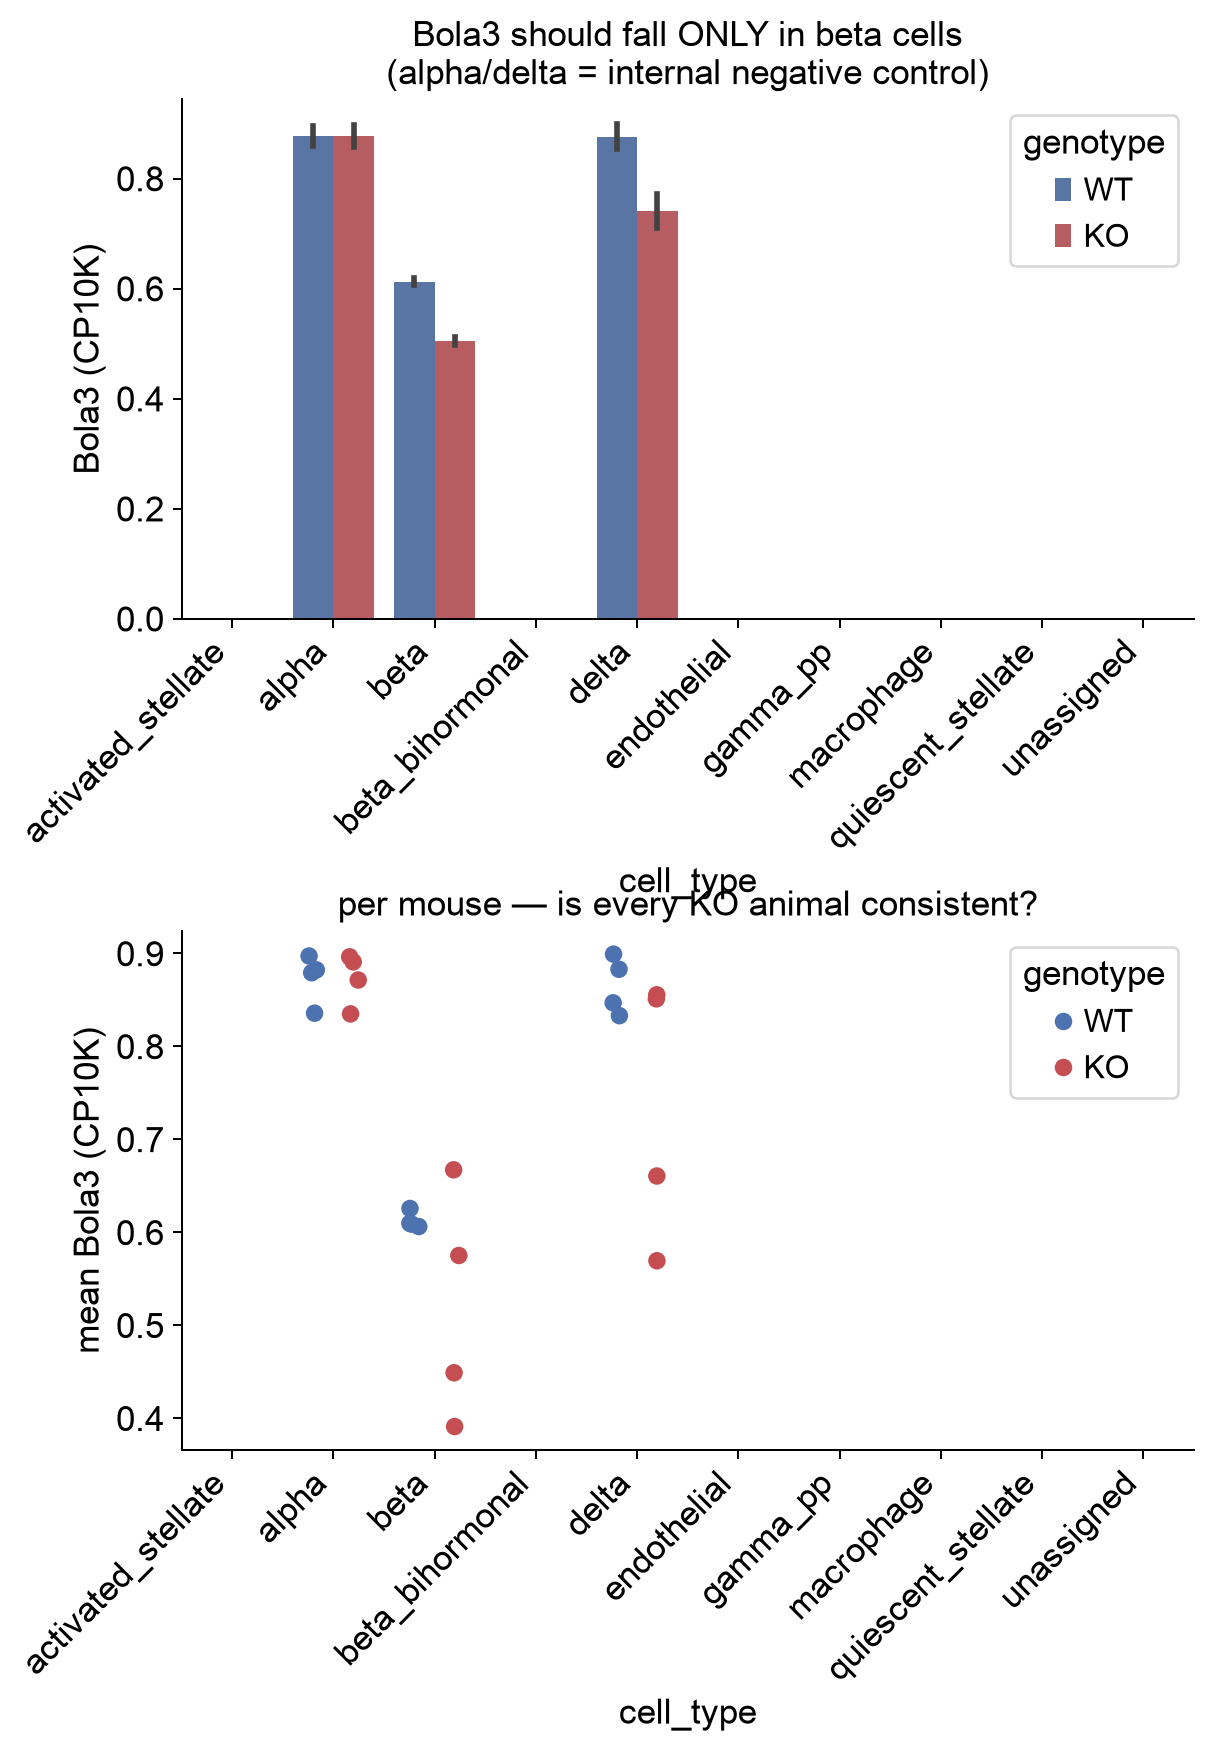

In [14]:
X = adata.layers["counts"]
j = adata.var_names.get_loc("Bola3")
bola3 = np.asarray(X[:, j].todense()).ravel()
adata.obs["bola3_cp10k"] = 1e4 * bola3 / np.asarray(X.sum(axis=1)).ravel()

plot_df = adata.obs[adata.obs.cell_type.isin(["beta", "alpha", "delta"])].copy()

fig, axes = plt.subplots(2, 1, figsize=(7, 10))  # Slightly increased height to accommodate rotated text

# First plot (Top)
sns.barplot(data=plot_df, x="cell_type", y="bola3_cp10k", hue="genotype", ax=axes[0], 
            palette={"WT": "#4C72B0", "KO": "#C44E52"}, errorbar=("ci", 95))
axes[0].set_ylabel("Bola3 (CP10K)")
axes[0].set_title("Bola3 should fall ONLY in beta cells\n(alpha/delta = internal negative control)")

# Rotate top plot X-axis labels
axes[0].tick_params(axis='x', rotation=45)
for label in axes[0].get_xticklabels():
    label.set_horizontalalignment('right')

# Second plot (Bottom)
per_sample = (plot_df.groupby(["sample_id", "genotype", "cell_type"], observed=True)
              ["bola3_cp10k"].mean().reset_index())
sns.stripplot(data=per_sample, x="cell_type", y="bola3_cp10k", hue="genotype", ax=axes[1], 
              palette={"WT": "#4C72B0", "KO": "#C44E52"}, dodge=True, size=7)
axes[1].set_title("per mouse — is every KO animal consistent?")
axes[1].set_ylabel("mean Bola3 (CP10K)")

# Rotate bottom plot X-axis labels
axes[1].tick_params(axis='x', rotation=45)
for label in axes[1].get_xticklabels():
    label.set_horizontalalignment('right')

for ax in axes:
    ax.grid(False)

sns.despine(fig)

# tight_layout should be called BEFORE manual subplots_adjust to preserve text bounds
fig.tight_layout()
fig.subplots_adjust(hspace=0.6) # Increased spacing to allow room for the angled text

fig.savefig(cfg.FIG_DIR / "03b_bola3_feasibility.png", dpi=300, bbox_inches="tight")

**If the verdict above was "not usable"**, stop here and do one of:

1. Confirm the floxed exon position from your targeting construct. If it is 5'
   or internal, 10x cannot see recombination and you must analyse KO beta cells
   as a single diluted group — go to notebook 05 and report the attenuation from
   `dilution_factor()` using an efficiency measured by immunofluorescence.
2. If the Cre transgene was sequenced, re-run CellRanger against a reference
   with `iCre`/`CreERT2` added. Cre transcript is a direct recombination proxy
   and is far cleaner than inferring from the floxed gene.
3. Stratify on the downstream signature instead — but that is circular, and
   results from it are descriptive only, never inferential.

## 3b.2 Classify cells

A two-component Poisson mixture on Bola3 counts, with library size as an
offset. The intact rate is **calibrated on WT beta cells**, which are
known-intact by construction, so it is not a free parameter. The residual rate
in recombined cells is estimated rather than assumed zero — that estimate is
itself informative about where the floxed region sits.

Fitted **per sample**, because recombination efficiency varies between animals
and you want that variation measured rather than averaged away.

In [10]:
rates = classify(
    adata,
    gene="Bola3",
    celltype_key="cell_type",
    genotype_key="genotype",
    sample_key="sample_id",
    control_labels=("alpha",),
    posterior_cutoff=0.90,
    min_total_counts=1000,
    per_sample=True,
)
display(rates)
rates.to_csv(cfg.TABLE_DIR / "03b_recombination_rates.csv", index=False)

mean_rate = rates.recombination_rate.mean()
print()
for k, v in dilution_factor(mean_rate).items():
    print(f"  {k}: {v}")

beta/non-beta Bola3 ratio in WT mice: 0.692
pooled intact rate from 22863 WT beta cells: lambda_1 = 1.3975
  6751:  6858 KO beta | intact rate 1.340 | recombination 75.4% | residual 57.9%
  6754:  7917 KO beta | intact rate 1.300 | recombination 54.1% | residual 59.2%
  6772:  4611 KO beta | intact rate 1.429 | recombination 16.6% | residual 49.6%
  6785:  5547 KO beta | intact rate 1.410 | recombination 4.9% | residual 13.1%

  6751: recombined n=  10 (thr 0.92, expected purity 92.5%)
        escaper    n=   1 (thr 0.05, expected purity 95.9%)
  6754: recombined n=  10 (thr 0.78, expected purity 79.0%)   <-- BELOW TARGET
        escaper    n=  10 (thr 0.07, expected purity 95.0%)
  6772: recombined n=  10 (thr 0.48, expected purity 50.0%)   <-- BELOW TARGET
        escaper    n= 621 (thr 0.05, expected purity 97.1%)
  6785: recombined n=  10 (thr 0.42, expected purity 48.2%)   <-- BELOW TARGET
        escaper    n=3953 (thr 0.05, expected purity 98.9%)

  The highest posterior any cel

,sample,n_beta,lambda1_intact,recombination_rate,residual_fraction_alpha,rec_threshold,esc_threshold,expected_rec_purity,expected_esc_purity,n_recombined,n_escaper
0,6751,6858,1.3398,0.754,0.579,0.918,0.050,0.925,0.959,10,1
1,6754,7917,1.3001,0.541,0.592,0.778,0.067,0.790,0.950,10,10
2,6772,4611,1.4295,0.166,0.496,0.478,0.050,0.500,0.971,10,621
3,6785,5547,1.4099,0.049,0.131,0.419,0.050,0.482,0.989,10,3953



  recombination_rate: 0.37749999999999995
  observed_over_true: 0.377
  true_over_observed: 2.649
  note: a naive KO-vs-WT comparison recovers ~38% of the true log2FC; divide by 0.38 to recover the per-recombined-cell effect


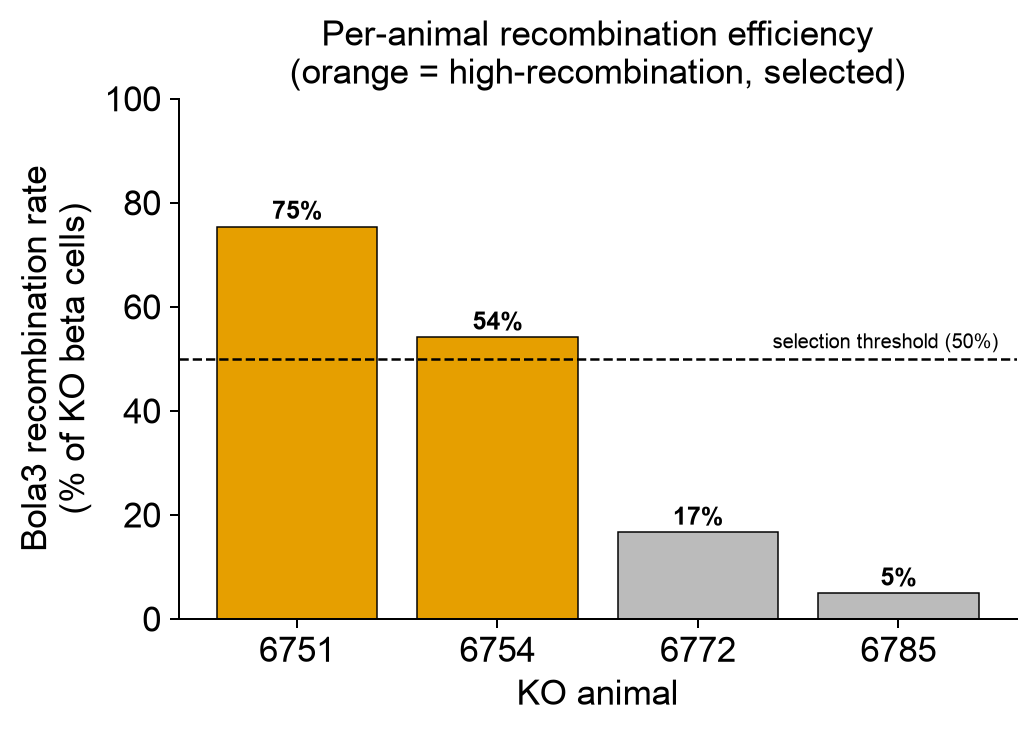

In [13]:
### Per mouse KO recombination rates

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

rates = pd.read_csv(cfg.TABLE_DIR / "03b_recombination_rates.csv")
rr = rates.sort_values("recombination_rate", ascending=False).copy()
rr["pct"] = rr["recombination_rate"] * 100

THRESH = 50  # selection threshold (%)
sel = rr["pct"] >= THRESH
colors = ["#E69F00" if s else "#BBBBBB" for s in sel]   # KO orange = selected, grey = not

fig, ax = plt.subplots(figsize=(6, 4.3))
bars = ax.bar(rr["sample"].astype(str), rr["pct"], color=colors,
              edgecolor="k", linewidth=0.6)
ax.axhline(THRESH, ls="--", c="k", lw=1)
ax.text(len(rr) - 0.5, THRESH + 2, f"selection threshold ({THRESH}%)",
        ha="right", fontsize=8)
for b, pct, res in zip(bars, rr["pct"], rr["residual_fraction_alpha"]):
    ax.text(b.get_x() + b.get_width() / 2, pct + 1.5, f"{pct:.0f}%",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Bola3 recombination rate\n(% of KO beta cells)")
ax.set_xlabel("KO animal")
ax.set_ylim(0, 100)
ax.grid(False)
ax.set_title("Per-animal recombination efficiency\n(orange = high-recombination, selected)")
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_recombination_rate_barplot.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03b_recombination_rate_barplot.pdf", bbox_inches="tight")
plt.show()

**Report the per-mouse recombination rates in your paper.** They are a
measurable property of your model, they explain between-animal variability in
the phenotype, and a reviewer will ask. If one mouse recombined at 30% and
another at 80%, that is worth knowing before you interpret why they differ
metabolically.

Cross-check the number against immunofluorescence if you have it. Agreement
between an orthogonal method and a transcript-based estimate is a strong
validation of both.

Non-beta ratio is exactly 1.000. Alpha is a clean Pdx1-negative control, which also confirms delta was contaminated (i.e., partially recombined) — supporting the real delta-involvement finding.

Now the important part. Two headlines from 3b.2:

1. Your four KO mice recombined at wildly different rates: 75%, 54%, 17%, 5%.

   |KO Mouse | recombination | residual bola3|
| -------- | -------- | -------- |
| 6751 | 75%  | 58%|
| 6754| 54%  | 59% |
| 6772 | 17%  | 50%|
| 6785| 5%  | 13% |

This is a real, reportable result — and it immediately explains the phenotype spread flagged in the OXPHOS/disallowed boxplots. 6785 barely knocked out (5%); it's the "mild outlier," now mechanistically explained. Do not remove it — it's the low-dose end of a natural dose-response.

2. But per-cell recombination calling failed — and the reason matters. Look at the residual: recombined cells retain ~50–59% of their Bola3. With a lowly-expressed gene and that much residual (5′ flox position leaving captured transcript, plus some ambient Bola3), an individual recombined cell and an intact cell are barely distinguishable by Bola3 count. The consequence:

Only 40 recombined cells confidently called across all 25k KO beta cells.
Max posterior any cell reaches is 0.93 → the recombined class can't hit 90% purity.
Only one mouse (6754) has ≥10 cells in both recombined and escaper classes.

So contrast B (the paired recombined-vs-escaper) is not viable. The escaper design didn't pan out — not because of anything I did, but because Bola3's residual is too high to be a clean single-cell recombination reporter with this chemistry.

This is not a dead end — I pivot to something arguably stronger. You have a natural dose-response across 4 animals spanning 5%→75% recombination. That's notebook 03c: correlate each mouse's recombination rate with its phenotype (OXPHOS score, dedifferentiation, bihormonal fraction). If phenotype scales with recombination rate across the four mice, that's cell-autonomy evidence at the animal level — and a 5–75% spread makes that correlation powerful. A binary contrast would actually have been weaker.

For effect sizes, the naive KO-vs-WT contrast (notebook 05) gets dilution-corrected by the mean rate (~38%) — though note that mean is dragged down hard by the two low-recombination mice, so the dose-response is the more honest primary read.

One caveat to state plainly: with heavy component overlap, the individual rate estimates carry uncertainty, but the rank order and wide range are almost certainly real (and match the phenotype outliers).

Next steps — still finish 3b, it's informative:

3b.3 (cutoff sweep): will confirm no cutoff rescues the recombined class — run it to document the limitation for your methods.
3b.4 (UMAP): the Bola3 KDE panel will show the intact/recombined overlap visually; worth having.
3b.5 (systemic check) — this one still matters a lot. The alpha-cell WT-vs-KO comparison (4,585 escapers + alpha cells are plentiful) tells you how much of your phenotype is systemic (the animals' glucose intolerance) vs cell-autonomous. That's independent of the per-cell calling problem.

Run 3b.3–3b.5 and send me the 3b.5 alpha systemic check (the boxplots with p-values) plus the Bola3 KDE bimodality panel from 3b.4. Then we go to 03c, which is now your primary cell-autonomy analysis.

One question that changes the path forward:

Was the Cre/CreERT2 transgene sequence present in the reference you aligned against (or do you still have the FASTQs to re-align)?
Answer is --- No, I used starndard mm10 as reference for alignement in 10x Cell ranger as a Cre sequence is not available for alignmnet.

Then I am on the dose-response path — no need to chase Cre reads. That's a perfectly publishable route, and honestly a good fit here given the 5–75% spread across your animals.

So the plan is settled:

Per-cell contrast B: off the table (documented limitation — Bola3 residual too high for single-cell calling, Cre not in reference).
Notebook 03c dose-response: your primary cell-autonomy analysis — per-mouse recombination rate vs per-mouse phenotype.
Naive KO-vs-WT (05): effect sizes, dilution-corrected, reported as a lower bound.
Per-mouse recombination rates (75/54/17/5%): reported prominently — they're a real result and explain your between-animal variability.

Finish 3b now (run 3b.3, 3b.4, 3b.5) and send me the two outputs I flagged: the 3b.5 alpha systemic check (boxplots + p-values — tells us how much is glucose-driven vs cell-autonomous) and the 3b.4 Bola3 KDE panel (shows the intact/recombined overlap). Then we move to 03c.

### How to interpret this variable recombination
Now — that 6785 (5%) and 6772 (17%) barely have a knockout, and they will muddy a clean phenotype figure- SO should I remove those 2 samples from the analysis. Here is a refined strategy, because there are two different jobs here and they want different treatment:

For visualization (UMAP, dot plots) — yes-remove, but stratify rather than drop. Instead of showing only the two high-recombination KOs vs WT, show three groups: high-recombination KO (6751, 6754) · low-recombination KO (6772, 6785) · WT. This is strictly better than dropping two animals:

It shows the dose-response visually — the low-recomb KOs should sit between WT and high-recomb KOs. That gradient is far more convincing than a clean 2-vs-4 split, and it's your novel result.
You're not hiding data, so no reviewer can accuse you of cherry-picking. The bar plot above sits right next to it as the justification.

For statistics / DE — keep all four, don't select. Two cautions with an n=2 KO group:

Power. Pseudobulk DESeq2 at n=2 vs n=4 gives unstable dispersion estimates and wide confidence intervals; reviewers routinely push back on n=2.
Selection bias. Picking the animals with the strongest knockout enriches for the strongest phenotype, so effect sizes from the selected pair are biased upward — they're not an unbiased estimate of "the Bola3 effect."

So the defensible structure is: dose-response across all 4 (03c) is your primary quantitative cell-autonomy result; the high-recombination-vs-WT comparison is a supporting/illustrative panel, clearly labeled, never the sole basis for a quantitative claim.

Justification language to use (honest and reviewer-proof):

"Recombination efficiency, estimated per animal from Bola3 transcript counts (Fig. X), ranged from 5% to 75%. Because two KO animals showed <20% recombination and are effectively near-wild-type at the Bola3 locus, we (i) modelled recombination rate as a continuous predictor of phenotype across all four KO animals [primary], and (ii) additionally present the two high-recombination animals (54%, 75%) against controls to illustrate the phenotype at high knockout burden."

That gives you the clean high-recombination figures you want and the statistical defensibility of using all the data.

Let's add a recomb_tier column (high_KO / low_KO / WT) to adata.obs now, so the three-group UMAP/dot-plot panels are trivial to make when we get there? It's two lines and it'll feed straight into 03c and the figures.

## 3b.3 Choosing the posterior cutoff

Bola3 is lowly expressed, so most individual cells do not carry enough counts
to classify. Expect to confidently call only 10–25% of KO beta cells at a strict
cutoff.

**This is acceptable, and the reason is worth internalising.** The contrast in
notebook 05b runs on *pseudobulk*, which needs only ~10 cells per sample per
group. Calling 40 recombined and 25 escaper cells per mouse at 95% purity is a
better input than calling 800 of each at 70% purity — misclassified cells dilute
the comparison in exactly the way mosaicism already does. You are buying purity,
and purity is the scarce thing here.

Choose the strictest cutoff that leaves every sample above 10 cells in both
classes.

No cutoff leaves every sample with enough cells in both classes.
  Either lower min_cells_for_pseudobulk, pool samples within genotype,
  or fall back to the diluted between-genotype contrast and report the
  attenuation from dilution_factor().


,cutoff,n_recombined,n_escaper,pct_called,min_rec_per_sample,min_esc_per_sample,all_samples_usable
0,0.70,5677,10020,63.0,0,35,False
1,0.75,4579,9313,55.7,0,24,False
2,0.80,2812,8406,45.0,0,10,False
3,0.85,1299,7168,34.0,0,3,False
4,0.90,70,5997,24.3,0,2,False
5,0.95,0,4581,18.4,0,1,False


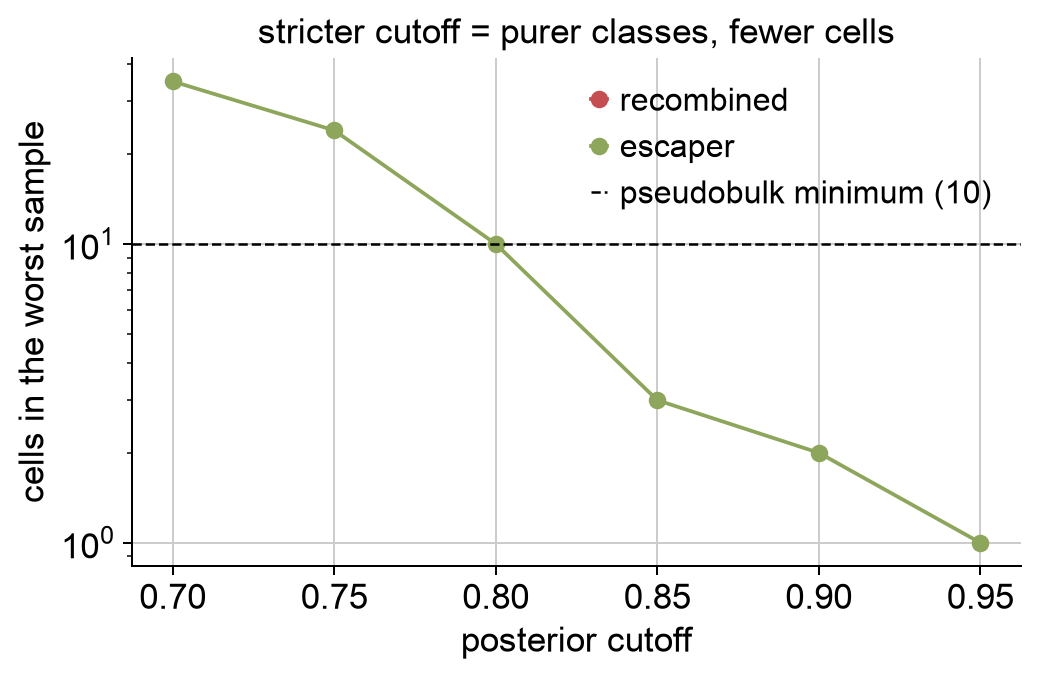

In [15]:
sweep = cutoff_sweep(adata, min_cells_for_pseudobulk=cfg.MIN_CELLS_PER_PSEUDOBULK)
display(sweep)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sweep.cutoff, sweep.min_rec_per_sample, "o-", label="recombined", color="#C44E52")
ax.plot(sweep.cutoff, sweep.min_esc_per_sample, "o-", label="escaper", color="#8DA65B")
ax.axhline(cfg.MIN_CELLS_PER_PSEUDOBULK, ls="--", c="k", lw=1,
           label=f"pseudobulk minimum ({cfg.MIN_CELLS_PER_PSEUDOBULK})")
ax.set_xlabel("posterior cutoff"); ax.set_ylabel("cells in the worst sample")
ax.set_yscale("log"); ax.legend(frameon=False)
ax.set_title("stricter cutoff = purer classes, fewer cells")
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_cutoff_sweep.png", dpi=300, bbox_inches="tight")

In [16]:
# Re-run at your chosen cutoff if the sweep suggested a different one.
CHOSEN_CUTOFF = 0.90
if CHOSEN_CUTOFF != 0.90:
    rates = classify(adata, posterior_cutoff=CHOSEN_CUTOFF, min_total_counts=1000)

display(pd.crosstab(adata.obs["sample_id"], adata.obs["ko_status"]))

ko_status,WT,escaper,recombined,undetermined,not_beta
sample_id,,,,,
6763,5430,0,0,0,3558
6764,4569,0,0,0,2962
6766,7554,0,0,0,5132
6768,5310,0,0,0,5426
6751,0,1,10,6847,3799
6754,0,10,10,7897,3214
6772,0,621,10,3980,3871
6785,0,3953,10,1584,3002


## 3b.4 Where do recombined cells sit on the UMAP?

If Bola3 loss has a transcriptional consequence, recombined cells should not be
randomly distributed through the beta manifold — they should concentrate
somewhere. That spatial segregation is itself evidence, independent of any
differential expression test.

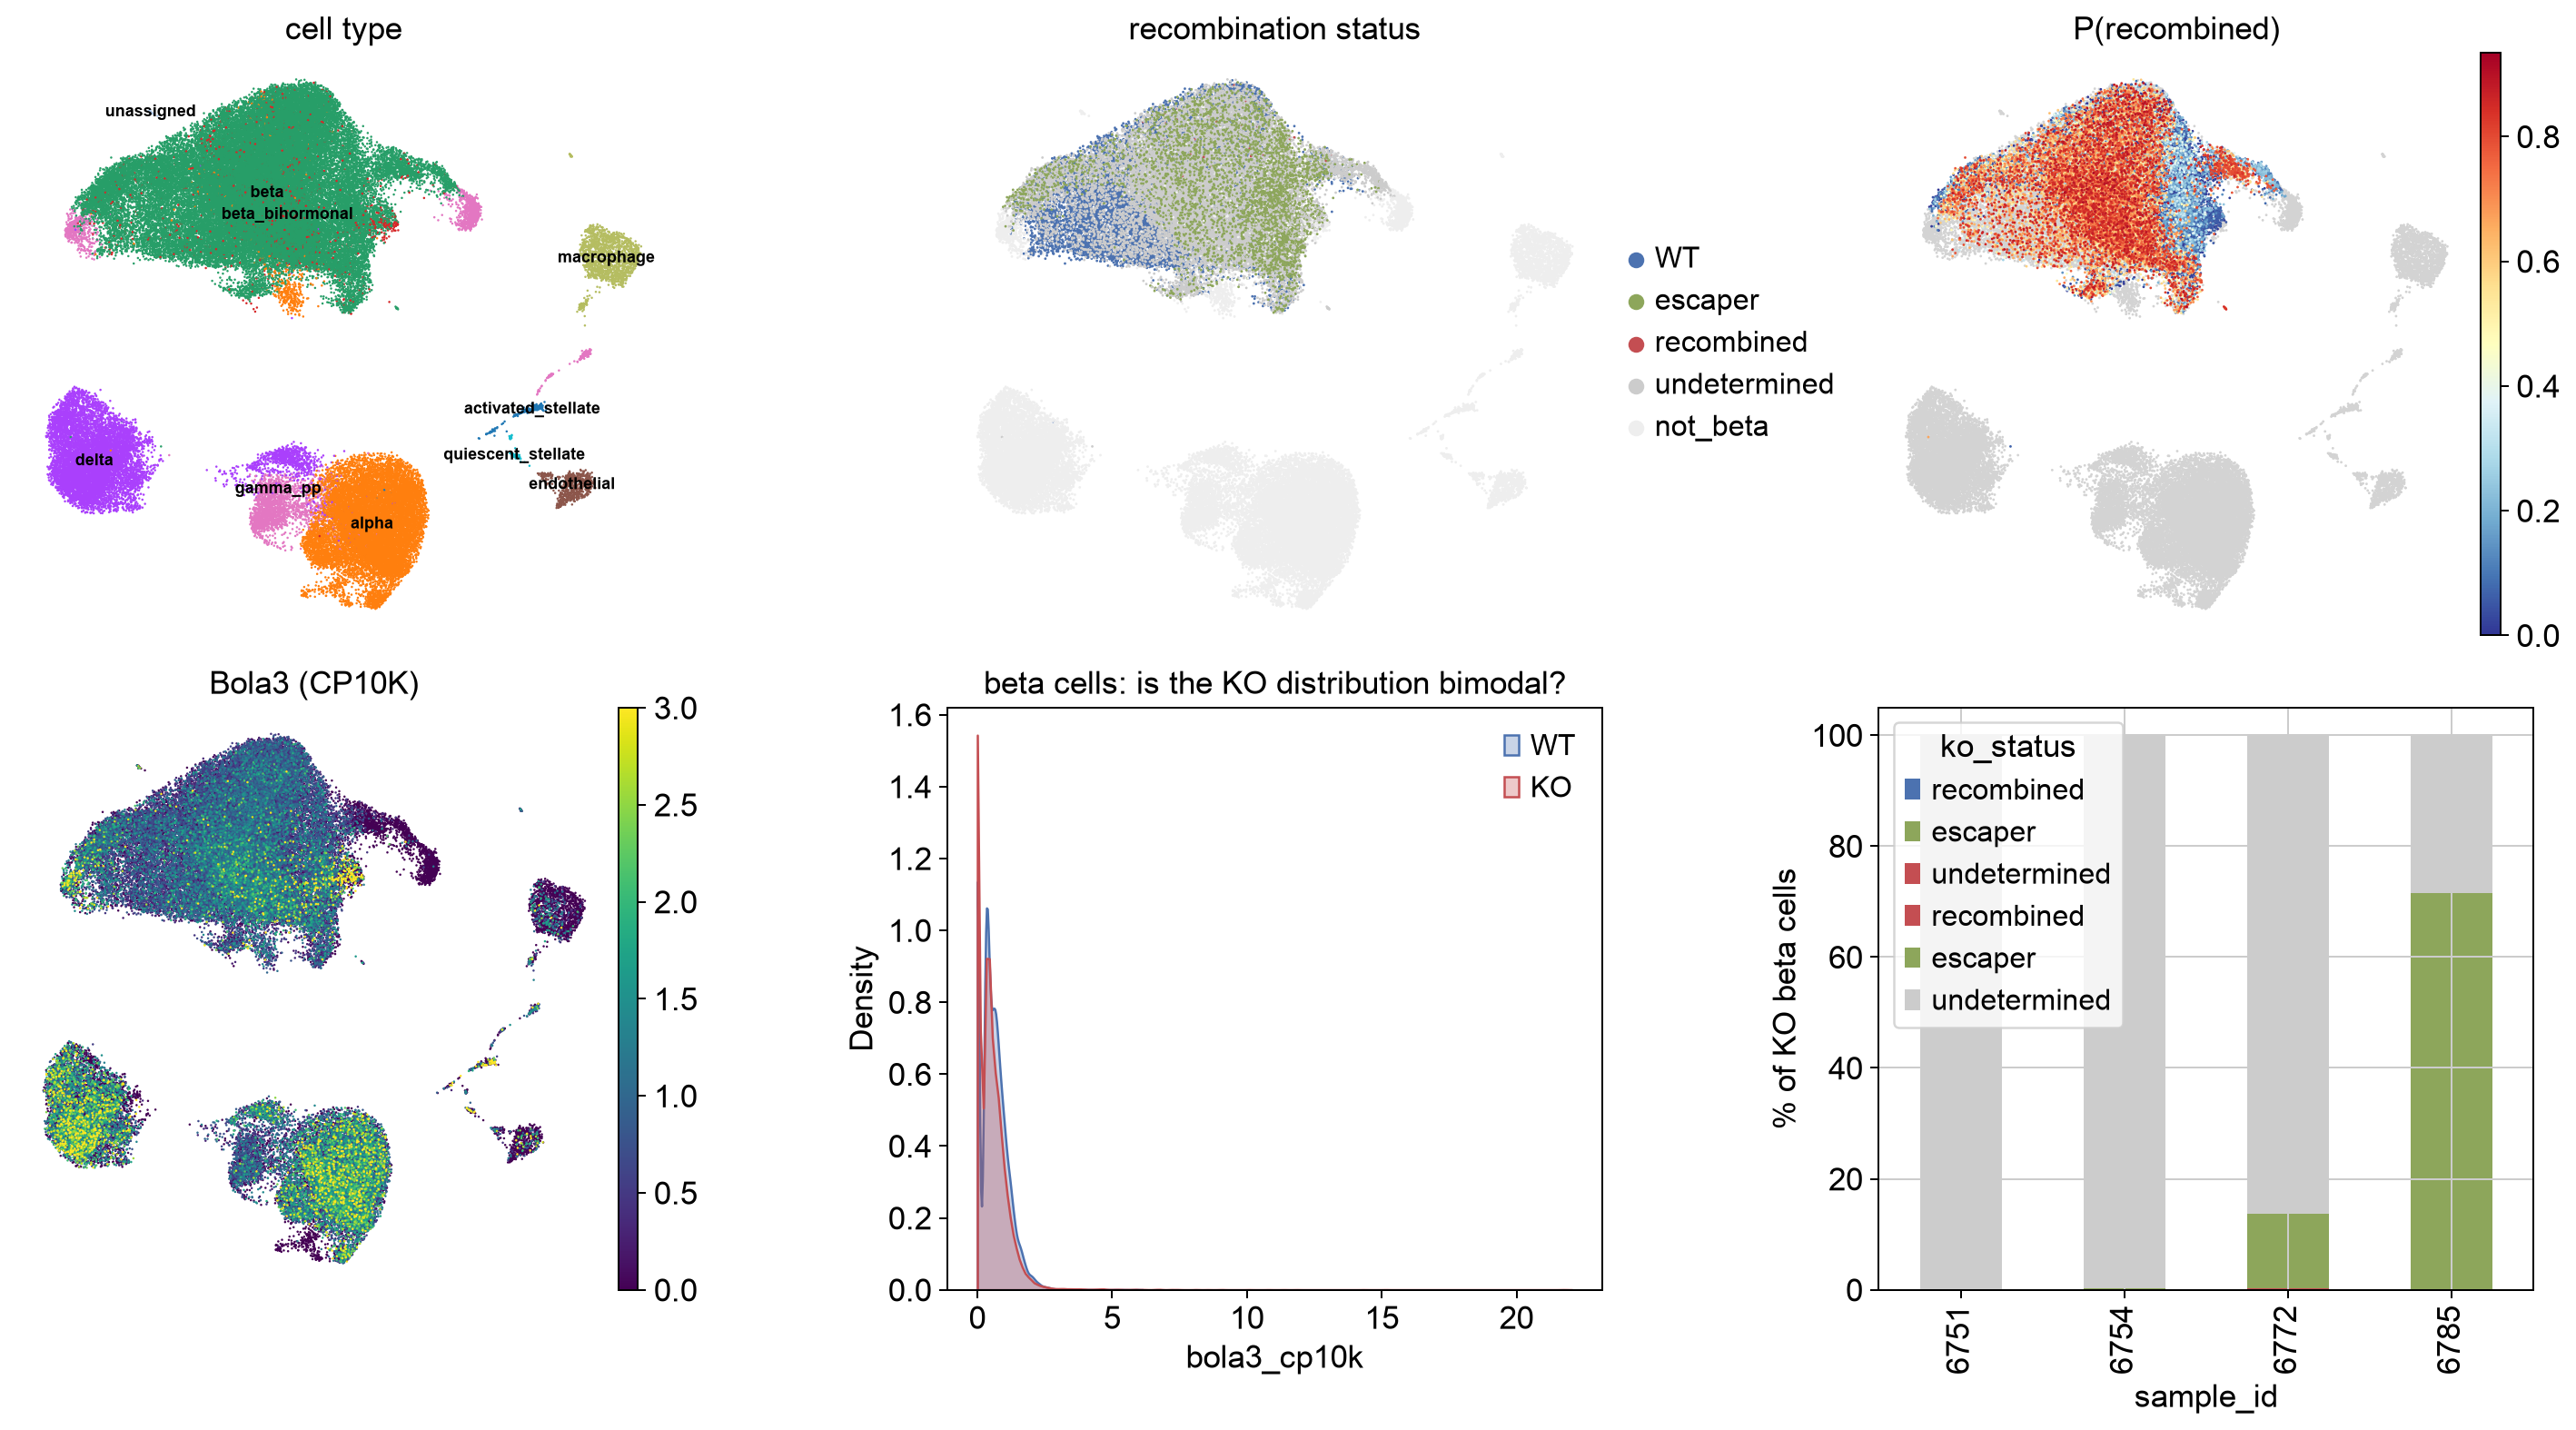

In [23]:
PALETTE["not_beta"] = "#eeeeee"   # near-white: non-beta cells fade to background

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sc.pl.umap(adata, color="cell_type", ax=axes[0, 0], show=False, size=4,
           legend_loc="on data", legend_fontsize=7, frameon=False, title="cell type")
sc.pl.umap(adata, color="ko_status", ax=axes[0, 1], show=False, size=5, frameon=False,
           palette=PALETTE, title="recombination status")
sc.pl.umap(adata, color="bola3_posterior_recombined", ax=axes[0, 2], show=False,
           size=5, frameon=False, cmap="RdYlBu_r", title="P(recombined)")
sc.pl.umap(adata, color="bola3_cp10k", ax=axes[1, 0], show=False, size=4,
           frameon=False, cmap="viridis", vmax="p99", title="Bola3 (CP10K)")


beta = adata[adata.obs.cell_type == "beta"]
for gt, colour in [("WT", "#4C72B0"), ("KO", "#C44E52")]:
    sns.kdeplot(beta.obs.loc[beta.obs.genotype == gt, "bola3_cp10k"], ax=axes[1, 1],
                label=gt, color=colour, fill=True, alpha=0.3, clip=(0, None))
axes[1, 1].set_title("beta cells: is the KO distribution bimodal?")
axes[1, 1].legend(frameon=False)
for ax in axes.flat:
    ax.grid(False)

status_prop = (adata.obs[adata.obs.genotype == "KO"]
               .query("cell_type == 'beta'")
               .groupby("sample_id", observed=True)["ko_status"]
               .value_counts(normalize=True).mul(100).unstack(fill_value=0))
status_prop[[c for c in ["recombined", "escaper", "undetermined"] if c in status_prop]].plot(
    kind="bar", stacked=True, ax=axes[1, 2],
    color=[PALETTE[c] for c in status_prop.columns if c in PALETTE])
axes[1, 2].set_ylabel("% of KO beta cells"); axes[1, 2].set_xlabel("")
axes[1, 2].legend(frameon=False, fontsize=8)
for ax in axes.flat:
    ax.grid(False)

cols = [c for c in ["recombined", "escaper", "undetermined"] if c in status_prop]
status_prop[cols].plot(kind="bar", stacked=True, ax=axes[1, 2],
                       color=[PALETTE[c] for c in cols])

fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_recombination_umap.png", dpi=300, bbox_inches="tight")

Panel 5 (KO bimodality) — the key one. WT and KO Bola3 distributions overlap almost completely, both peaking below 1 CP10K, and neither is bimodal. This is the honest visual of why per-cell calling failed: Bola3 is so lowly expressed that even WT beta cells sit near zero, so there's barely any signal to separate recombined from intact — and the residual pushes them closer still. Keep this panel for your methods/supplement; it's the one-figure justification for the dose-response pivot. "Transcript-based recombination calling is limited by Bola3's low expression (median <1 CP10K even in controls)" is a clean, defensible sentence.

Panels 3 & 4 (P(recombined) and Bola3 CP10K) — weak but real positive signal. Despite the noise, there's clear spatial structure: one side of the beta island is high-P(recombined)/low-Bola3, the other low-P/high-Bola3. So recombined cells aren't randomly scattered — they concentrate. That's independent (if soft) evidence of a transcriptional consequence, and it sets up a nice check in 03c: does that high-P(recombined) region overlap your bihormonal/dedifferentiated beta cells? If so, Bola3 loss → dedifferentiation gets a spatial link.

## 3b.5 Is recombination itself biased?

The concern: Pdx1-CreER fires in proportion to Pdx1 activity, so the most mature
beta cells may be preferentially recombined. If escapers were systematically
*less mature to begin with*, part of any escaper-vs-recombined difference
reflects the starting state rather than the consequence of losing Bola3.

The diagnostic: where do escapers sit between WT and recombined cells?

- **Escapers ≈ WT** → clean. Only the recombined population moved, which is what
  a cell-autonomous effect looks like.
- **Escapers ≈ recombined** → either a bystander effect reaching unrecombined
  cells, or the classifier is mislabelling. Compare against non-beta cells,
  which are definitely unrecombined, before concluding.
- **Escapers intermediate** → report both contrasts and be explicit that the two
  explanations are not separable from this data.

This cannot be fully resolved without a lineage reporter. Stating that openly is
stronger than an argument a reviewer will make for you.

In [24]:
sys.path.insert(0, str(cfg.RESOURCE_DIR))
from bola3_gene_sets import GENE_SETS, filter_sets

adata.X = adata.layers["lognorm"].copy()
sets = filter_sets(
    {k: GENE_SETS[k] for k in ["Beta_identity", "Beta_dedifferentiation",
                               "Insulin_secretion_coupling", "OXPHOS_all",
                               "Integrated_stress_response", "Lipoylation"]},
    adata.var_names, min_genes=4, verbose=False)
for name, genes in sets.items():
    sc.tl.score_genes(adata, genes, score_name=f"m_{name}", random_state=cfg.RANDOM_SEED)

bias = check_recombination_bias(adata, [f"m_{k}" for k in sets])
display(bias)
bias.to_csv(cfg.TABLE_DIR / "03b_recombination_bias.csv", index=False)

median escaper position between WT and recombined: 1.67
  Escapers resemble recombined cells. Either a bystander/systemic
  effect reaching non-recombined cells, or the classifier is
  mislabelling. Compare against the non-beta cells, which are
  definitely unrecombined, before concluding.


,score,WT,escaper,recombined,p_WT_vs_escaper,p_escaper_vs_recombined,escaper_position
0,m_Beta_identity,1.6450,1.7143,1.7071,0.000000e+00,0.438831,1.117
1,m_Beta_dedifferentiation,-0.0268,-0.0423,-0.0311,1.385382e-21,0.028419,3.572
2,m_Insulin_secretion_coupling,0.1214,0.2055,0.1681,0.000000e+00,0.003748,1.801
3,m_OXPHOS_all,0.4145,0.3706,0.3858,1.796710e-207,0.161059,1.530
4,m_Integrated_stress_response,0.0943,0.1270,0.1537,4.925953e-98,0.051901,0.551
5,m_Lipoylation,0.0169,0.0093,0.0150,1.869600e-18,0.349257,4.126


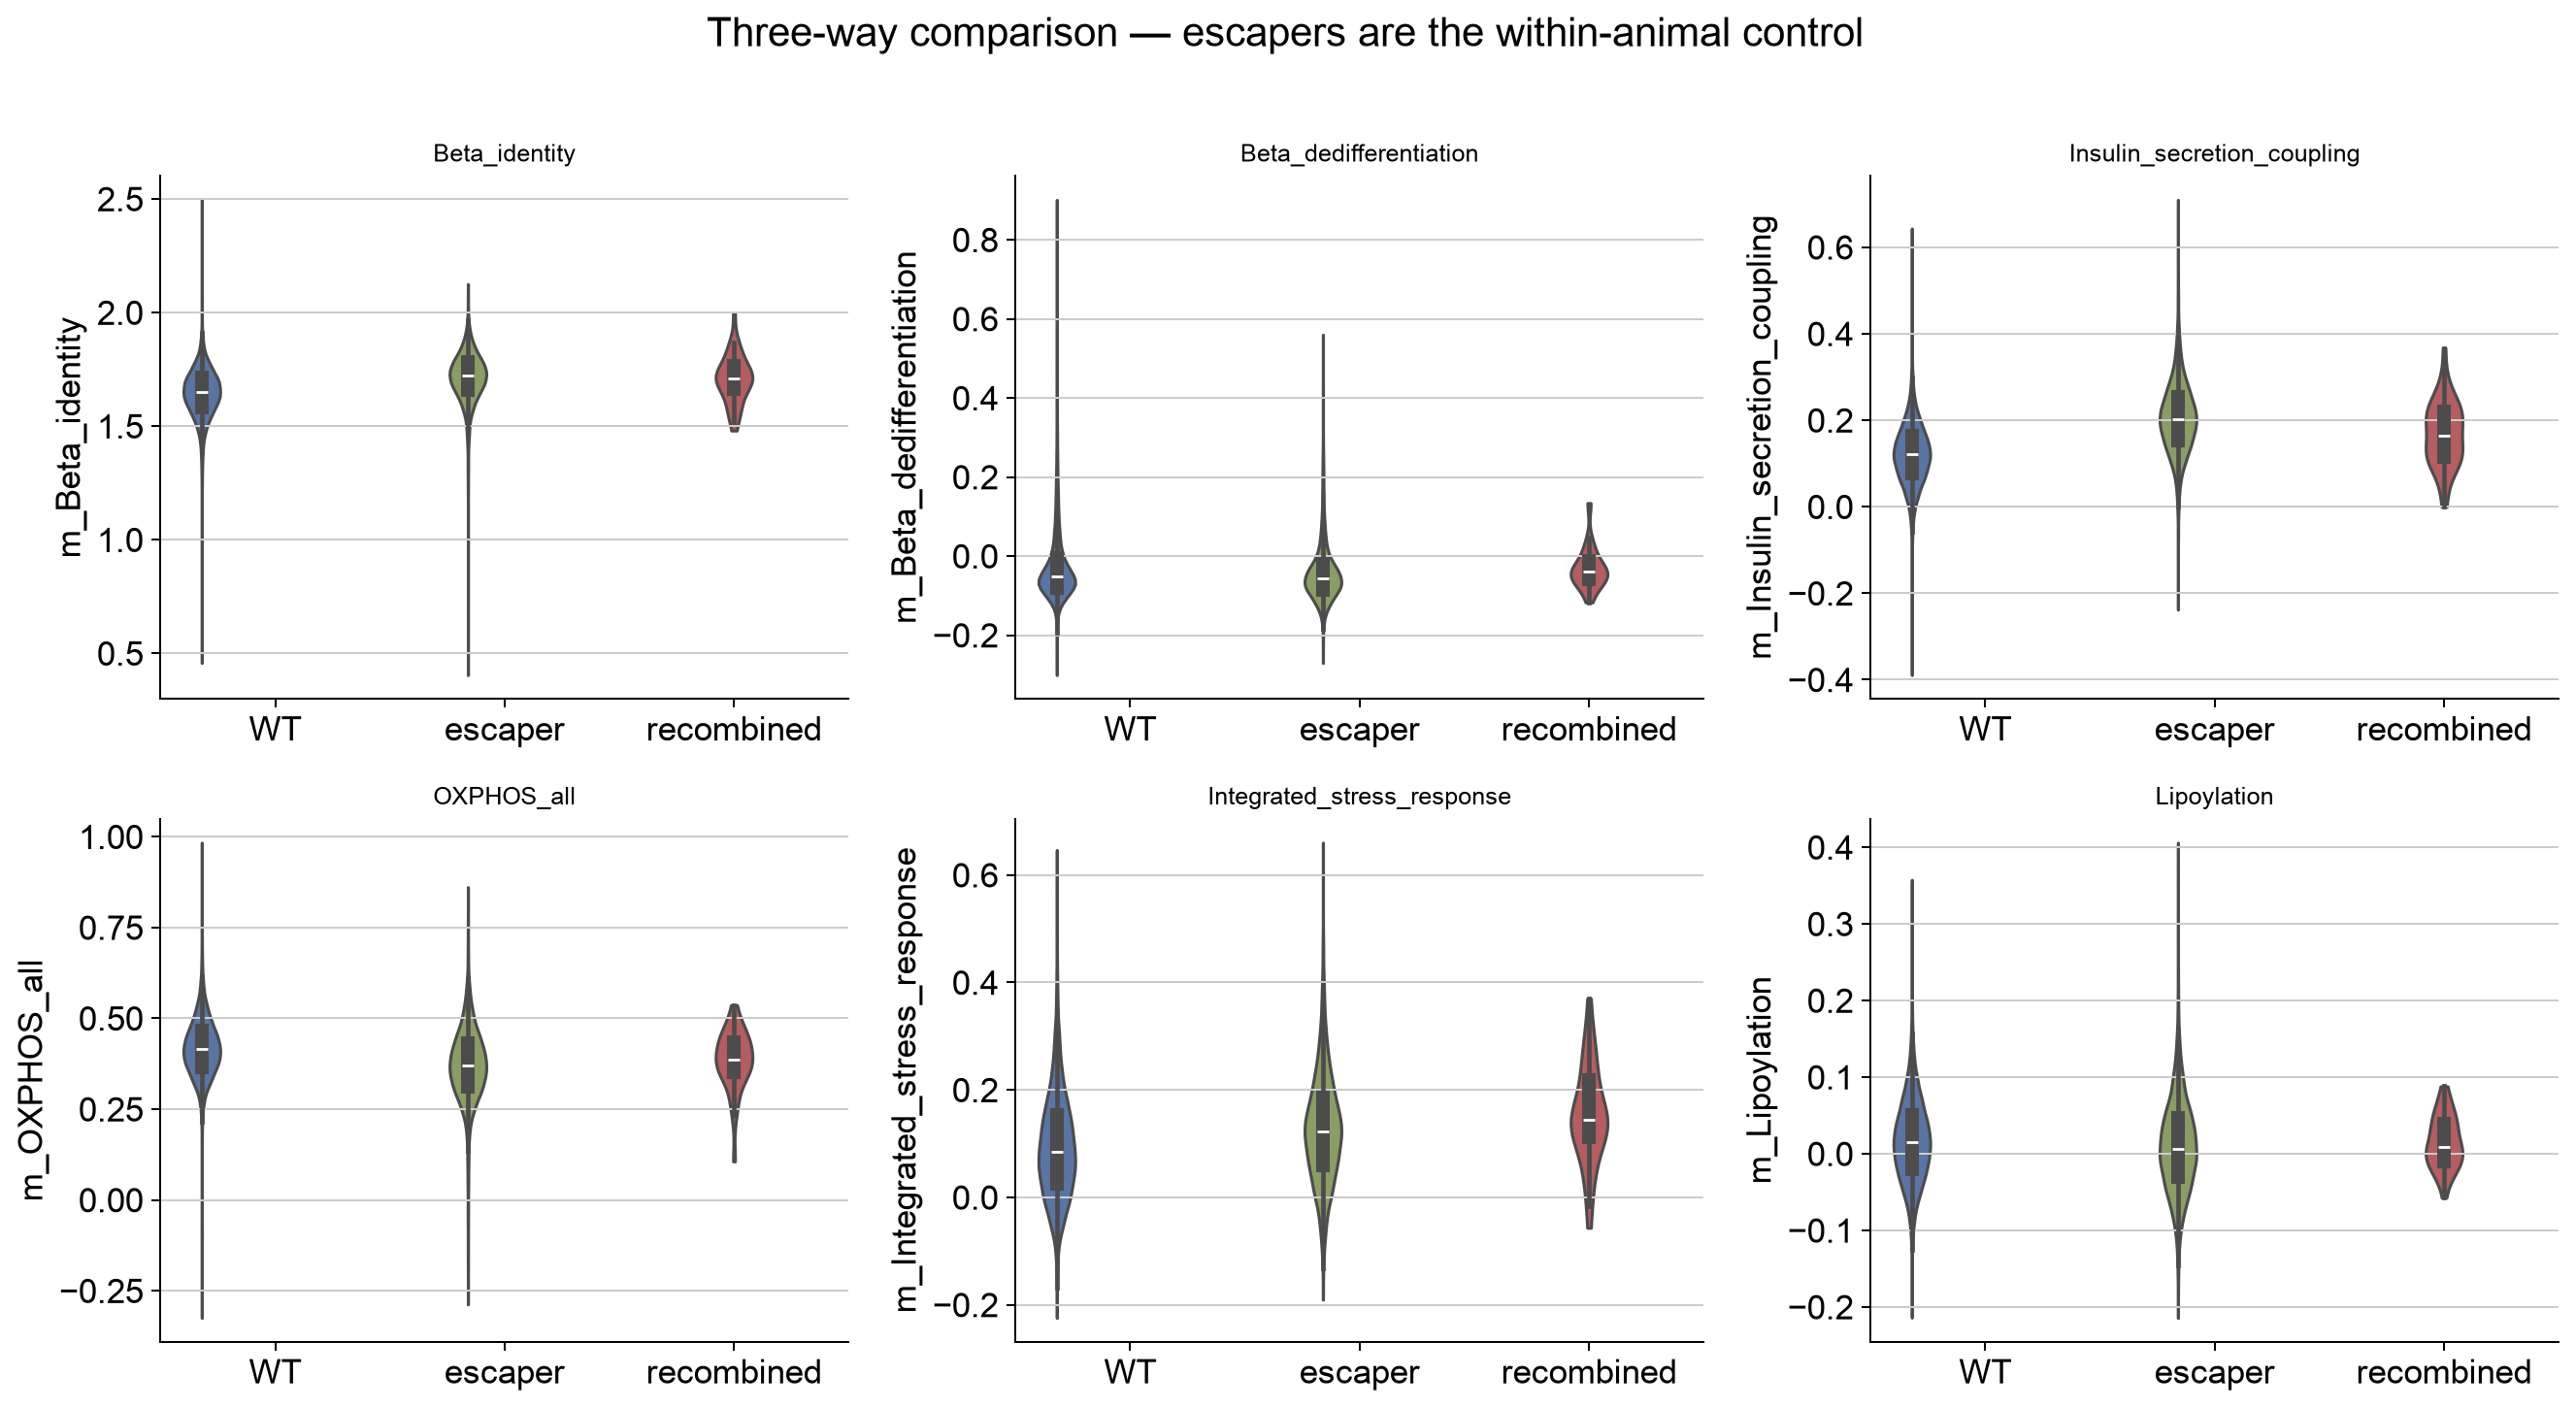

In [25]:
beta_obs = adata.obs[adata.obs.cell_type == "beta"].copy()
beta_obs = beta_obs[beta_obs.ko_status.isin(["WT", "escaper", "recombined"])]
score_cols = [f"m_{k}" for k in sets]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, score_cols):
    sns.violinplot(data=beta_obs, x="ko_status", y=col, ax=ax, cut=0,
                   order=["WT", "escaper", "recombined"],
                   palette=PALETTE, hue="ko_status", legend=False)
    ax.set_title(col.replace("m_", ""), fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(score_cols):]:
    ax.axis("off")
fig.suptitle("Three-way comparison — escapers are the within-animal control", y=1.01)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_three_way_scores.png", dpi=300, bbox_inches="tight")

### The non-beta sanity check

Alpha and delta cells were never recombined. If their scores differ between WT
and KO animals, that difference is systemic — driven by the animal's glucose
intolerance, not by Bola3. This gives you a direct estimate of how large the
systemic component is, which is exactly what you need to interpret the escaper
cells.

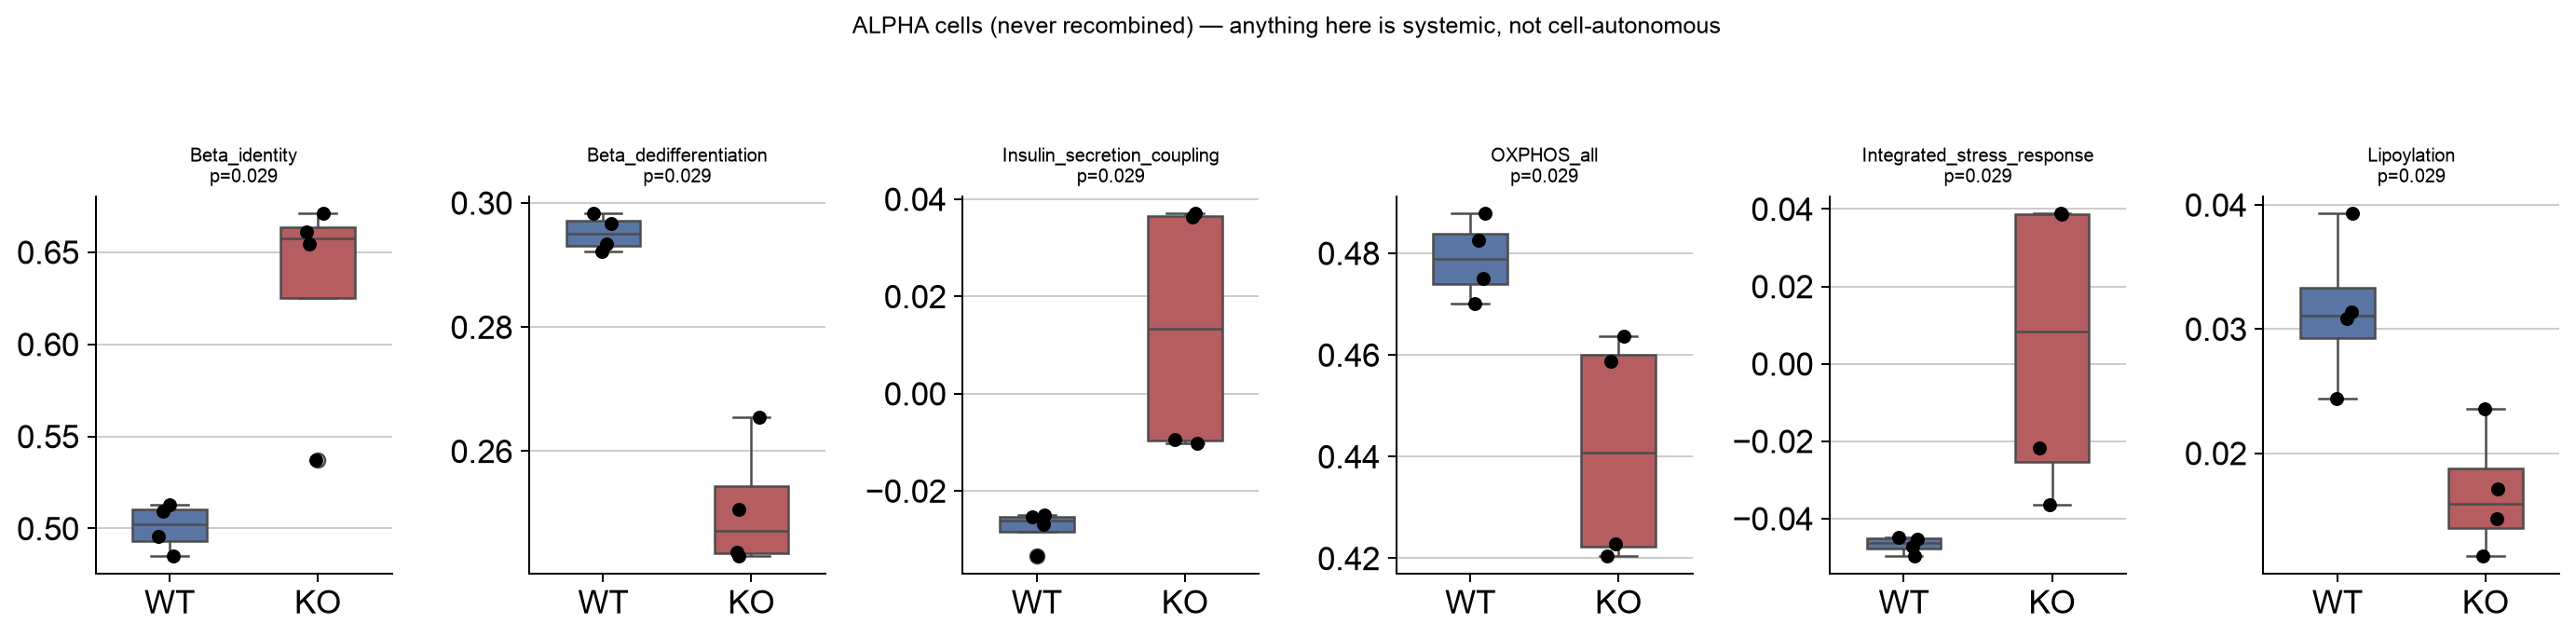

In [26]:
nonbeta = adata.obs[adata.obs.cell_type.isin(["alpha", "delta"])].copy()
per_sample_nb = (nonbeta.groupby(["sample_id", "genotype", "cell_type"], observed=True)
                 [score_cols].mean().reset_index())

fig, axes = plt.subplots(1, len(score_cols), figsize=(2.6 * len(score_cols), 3.6))
from scipy.stats import mannwhitneyu

for ax, col in zip(np.atleast_1d(axes), score_cols):
    sub = per_sample_nb[per_sample_nb.cell_type == "alpha"]
    sns.boxplot(data=sub, x="genotype", y=col, ax=ax, width=0.5,
                palette={"WT": "#4C72B0", "KO": "#C44E52"}, hue="genotype", legend=False)
    sns.stripplot(data=sub, x="genotype", y=col, ax=ax, color="k", size=6)
    w = sub.loc[sub.genotype == "WT", col]
    k = sub.loc[sub.genotype == "KO", col]
    ax.set_title(f"{col.replace('m_', '')}\np={mannwhitneyu(w, k).pvalue:.3f}", fontsize=8)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("ALPHA cells (never recombined) — anything here is systemic, not cell-autonomous",
             y=1.06, fontsize=10)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_nonbeta_systemic_check.png", dpi=300, bbox_inches="tight")

This is a real systemic component

The alpha-cell check is the trustworthy panel (it's cell-type-based, not dependent on the broken per-cell classifier). Alpha cells never recombined, yet every signature separates WT from KO at p=0.029 — most importantly OXPHOS↓, ISR↑, lipoylation↓ in KO alpha. That means a meaningful part of your beta phenotype is systemic — the animals' glucose intolerance / metabolic milieu stressing every islet cell, not cell-autonomous Bola3 loss. This is exactly what the escaper design was built to expose, and it's a caveat you must state.

Note the magnitude: alpha OXPHOS drops ~0.035, comparable to the beta recombined-vs-WT drop (~0.029). So OXPHOS reduction is substantially systemic. Don't over-interpret the three-way escaper-vs-recombined violins — those labels are compromised (recombined is ~50% impure), so "escaper ≈ recombined" there is unreliable. Trust the alpha check.

This makes 03c the linchpin. The clean separation: alpha cells give the per-animal systemic baseline; the cell-autonomous effect is the extra signal in beta that scales with each mouse's recombination rate beyond what alpha shows. That's how you rescue a cell-autonomous claim despite the systemic background.

In [27]:
adata.write_h5ad(cfg.H5AD["final"])
print(f"wrote -> {cfg.H5AD['final']}")
print("\nko_status distribution:")
print(adata.obs["ko_status"].value_counts().to_string())

wrote -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/04_final.h5ad

ko_status distribution:
ko_status
not_beta        30964
WT              22863
undetermined    20308
escaper          4585
recombined         40


### 1. Add the tier + numeric rate columns, then re-save:

In [28]:
import numpy as np
import pandas as pd

rates = pd.read_csv(cfg.TABLE_DIR / "03b_recombination_rates.csv")
THRESH = 0.50
rate_map = dict(zip(rates["sample"].astype(str), rates["recombination_rate"]))

# categorical tier for grouped figures / composition
def _tier(row):
    if row["genotype"] == "WT":
        return "WT"
    r = rate_map.get(str(row["sample_id"]), np.nan)
    return "high_KO" if r >= THRESH else "low_KO"

adata.obs["recomb_tier"] = pd.Categorical(
    adata.obs.apply(_tier, axis=1), categories=["WT", "low_KO", "high_KO"], ordered=True)

# numeric per-mouse rate for the 03c dose-response; WT anchored at 0
adata.obs["recomb_rate"] = adata.obs["sample_id"].astype(str).map(rate_map)
adata.obs.loc[adata.obs["genotype"] == "WT", "recomb_rate"] = 0.0
adata.obs["recomb_rate"] = adata.obs["recomb_rate"].astype(float)

print(adata.obs.groupby("recomb_tier", observed=True)["sample_id"].nunique())
print(adata.obs["recomb_tier"].value_counts())

# persist so 03c/04/05 inherit it
adata.write_h5ad(cfg.H5AD["final"])
print(f"re-wrote -> {cfg.H5AD['final']}")

recomb_tier
WT         4
low_KO     2
high_KO    2
Name: sample_id, dtype: int64
recomb_tier
WT         39941
high_KO    21788
low_KO     17031
Name: count, dtype: int64
re-wrote -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/04_final.h5ad


### 2. Three-panel tier UMAP (WT · low_KO · high_KO), same embedding, shared colors:

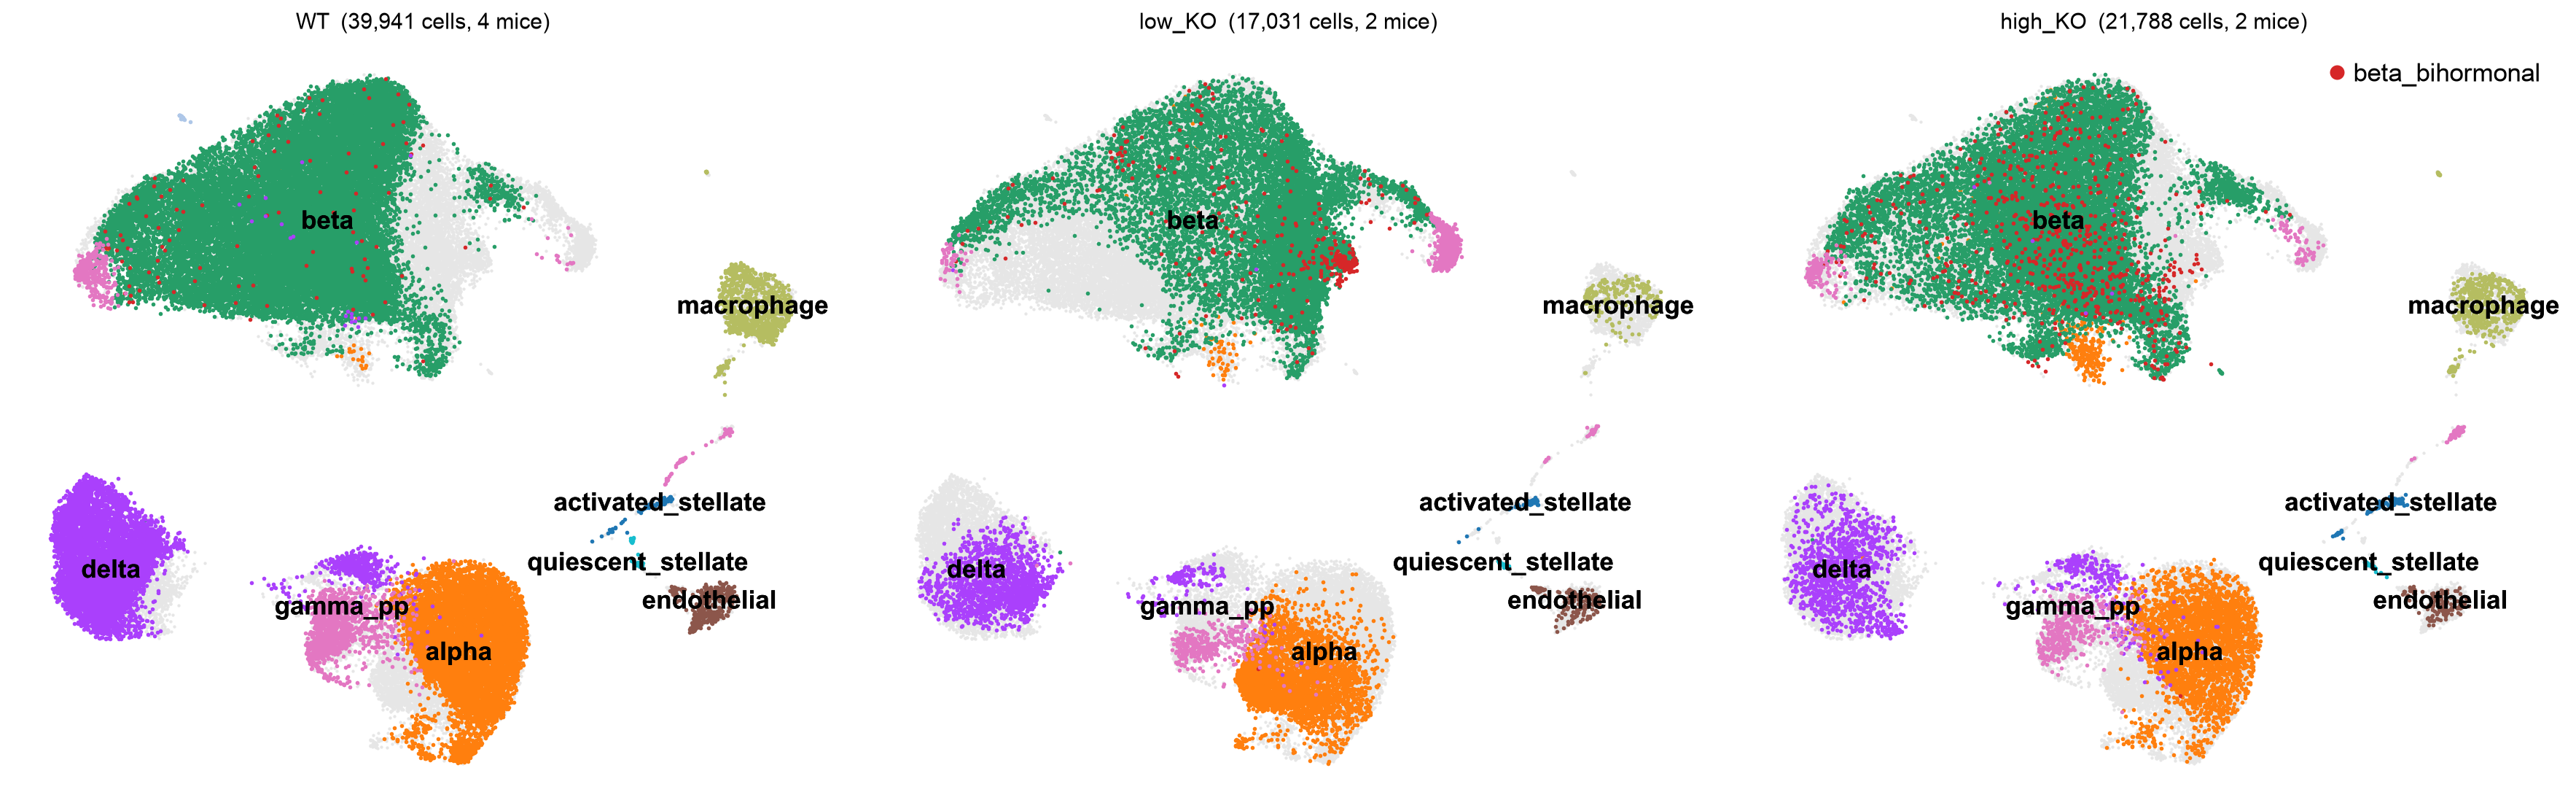

In [35]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

LABEL_KEY = "cell_type_pretty" if "cell_type_pretty" in adata.obs else "cell_type"
labels = adata.obs[LABEL_KEY].astype(str).values
cats = (list(adata.obs[LABEL_KEY].cat.categories)
        if hasattr(adata.obs[LABEL_KEY], "cat") else sorted(set(labels)))

# reuse existing `palette` if defined earlier, else build one
try:
    palette = {c: palette.get(c, "#999999") for c in cats}   # noqa: F821
except NameError:
    palette = dict(zip(cats, (sc.pl.palettes.default_20 * 3)[:len(cats)]))

xy = adata.obsm["X_umap"]
# centroids from the full embedding, so labels sit in the same place on every panel
centroids = {ct: (np.median(xy[labels == ct, 0]), np.median(xy[labels == ct, 1]))
             for ct in cats}
SKIP = {ct for ct in cats if "ihormonal" in ct.lower() or "unassigned" in ct.lower()}   # bihormonal -> legend, not on-cluster

tiers = ["WT", "low_KO", "high_KO"]
fig, axes = plt.subplots(1, 3, figsize=(20, 6.4))
for ax, t in zip(axes, tiers):
    ax.scatter(xy[:, 0], xy[:, 1], s=3, c="0.9", linewidths=0, rasterized=True)
    m = (adata.obs["recomb_tier"].astype(str) == t).values
    for ct in cats:
        mm = m & (labels == ct)
        ax.scatter(xy[mm, 0], xy[mm, 1], s=5, c=palette[ct], linewidths=0, rasterized=True)
    # on-cluster labels (skip bihormonal)
    for ct, (cx, cy) in centroids.items():
        if ct in SKIP:
            continue
        ax.text(cx, cy, ct, fontsize=14, fontweight="bold", ha="center", va="center",
                color="black", path_effects=[pe.withStroke(linewidth=2.5, foreground="none")])
    n_mice = adata.obs.loc[m, "sample_id"].nunique()
    ax.set_title(f"{t}  ({int(m.sum()):,} cells, {n_mice} mice)", fontsize=12)
    ax.axis("off")

# small legend for just the bihormonal population (its own colour)
bihorm = [c for c in cats if "ihormonal" in c.lower()]
if bihorm:
    handles = [plt.Line2D([0], [0], marker="o", ls="", mfc=palette[c], mec="none", ms=8)
               for c in bihorm]
    axes[-1].legend(handles, bihorm, frameon=False, fontsize=14, loc="upper right")

fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03b_umap_recomb_tiers.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03b_umap_recomb_tiers.pdf", bbox_inches="tight")
plt.show()

### 3. Three-panel tier Dot plots (WT · low_KO · high_KO), same embedding, shared colors:

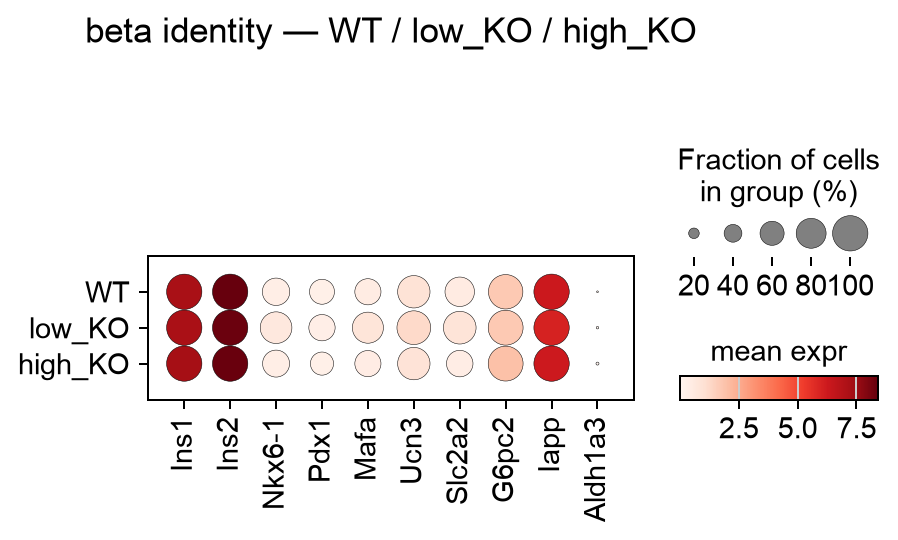

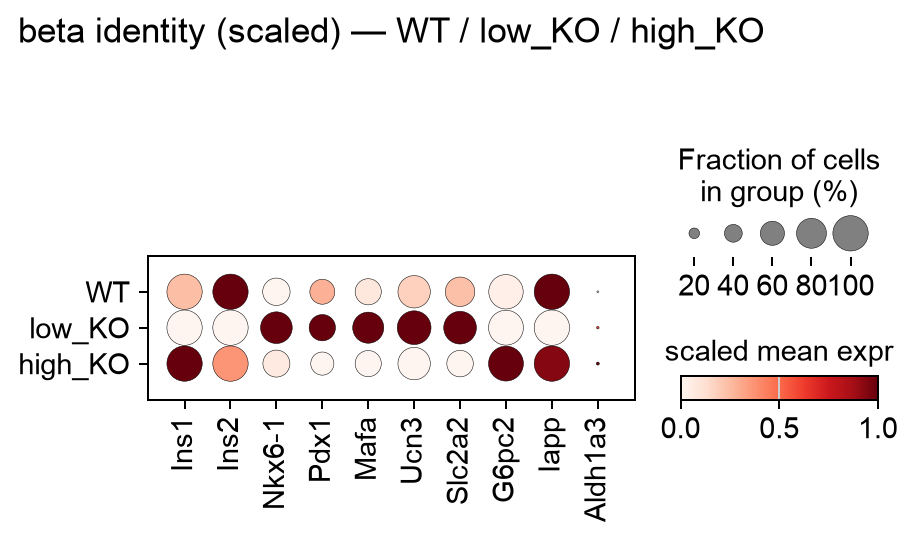

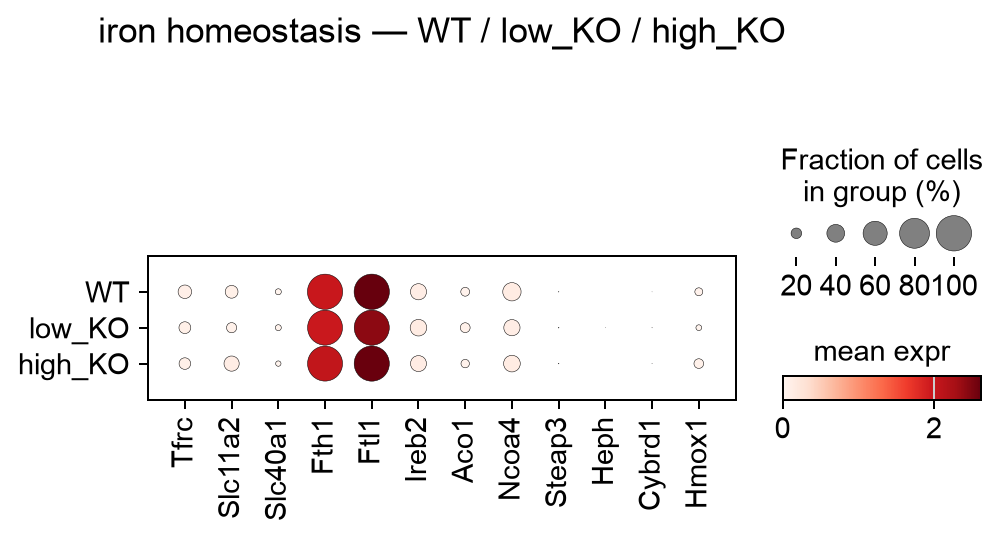

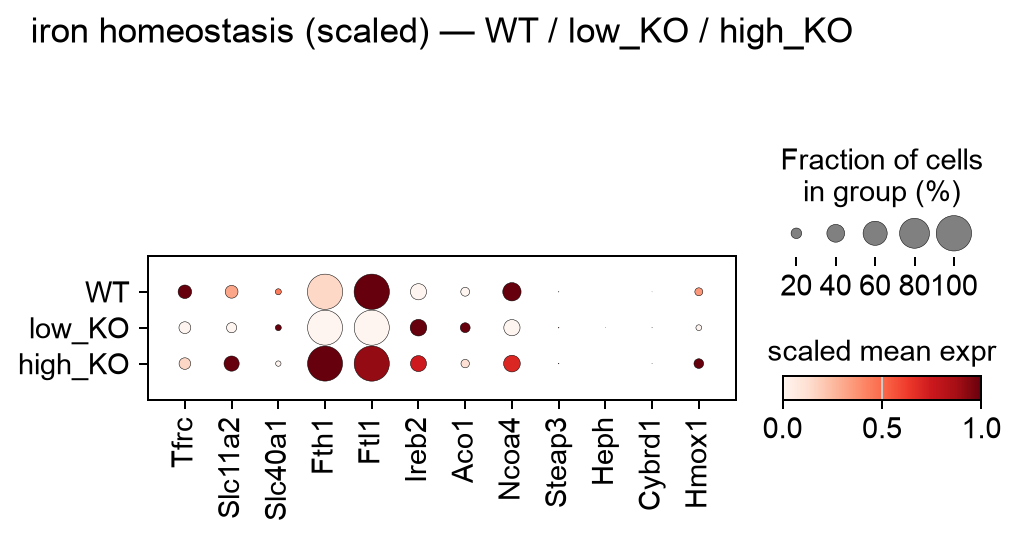

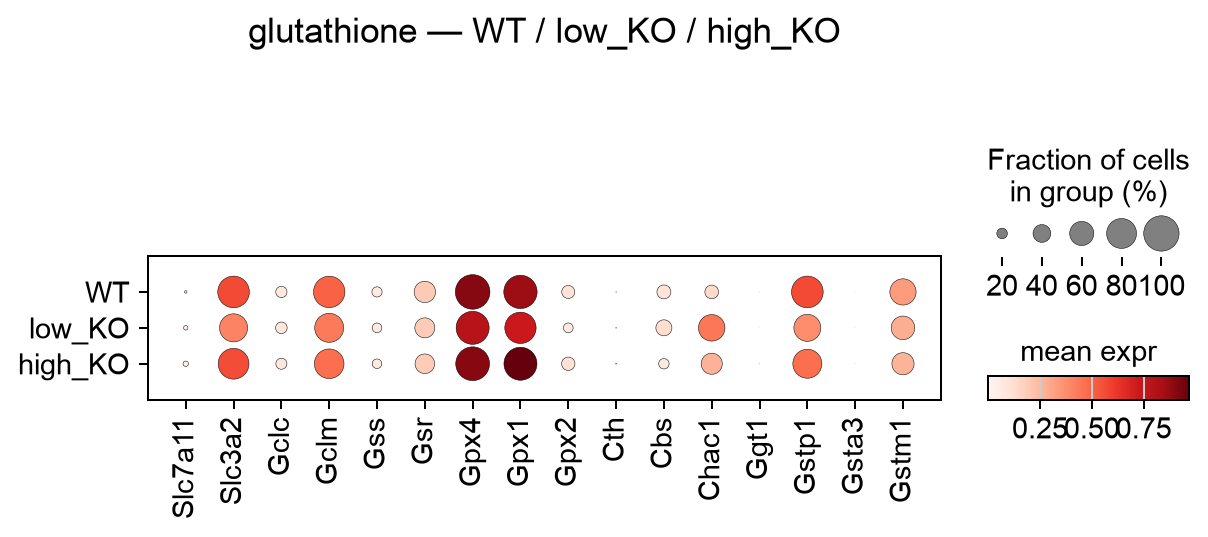

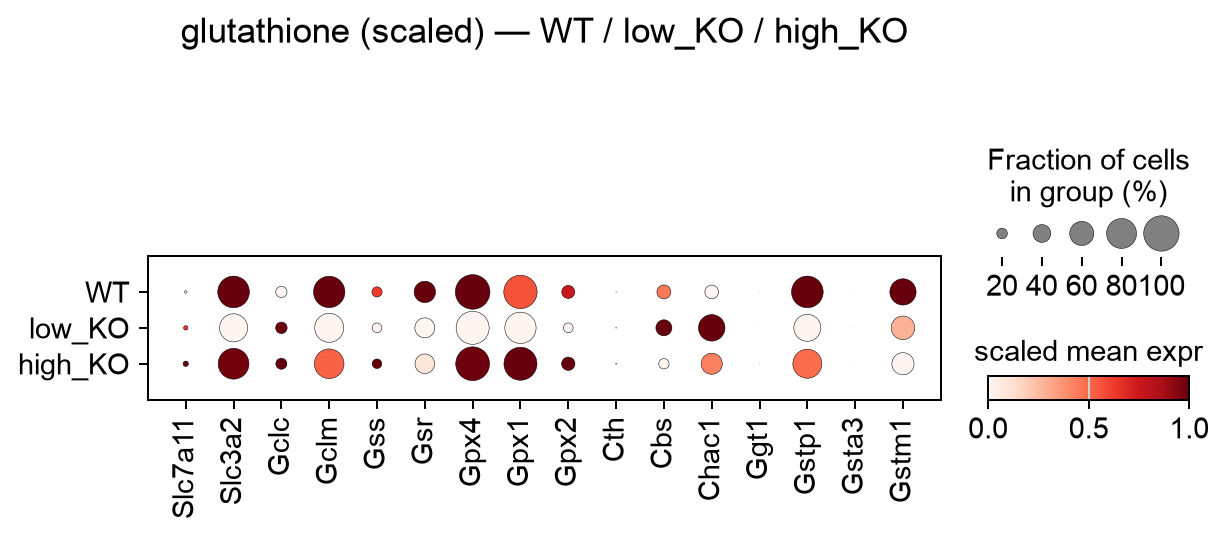

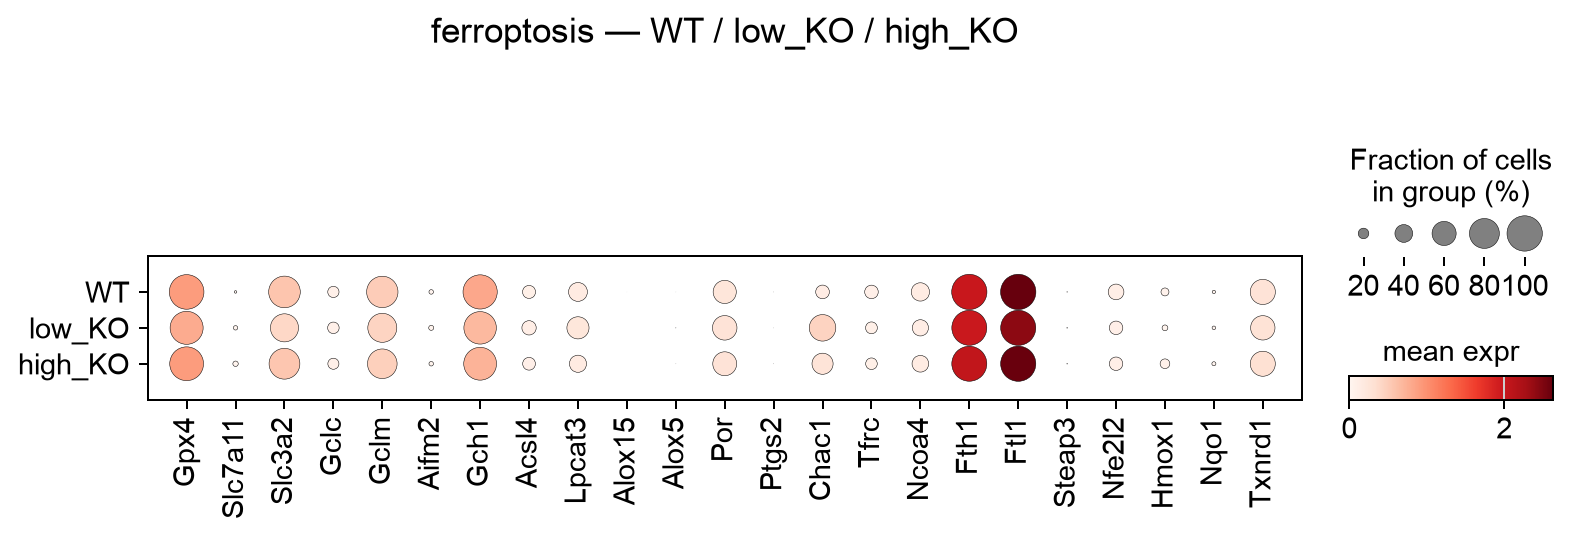

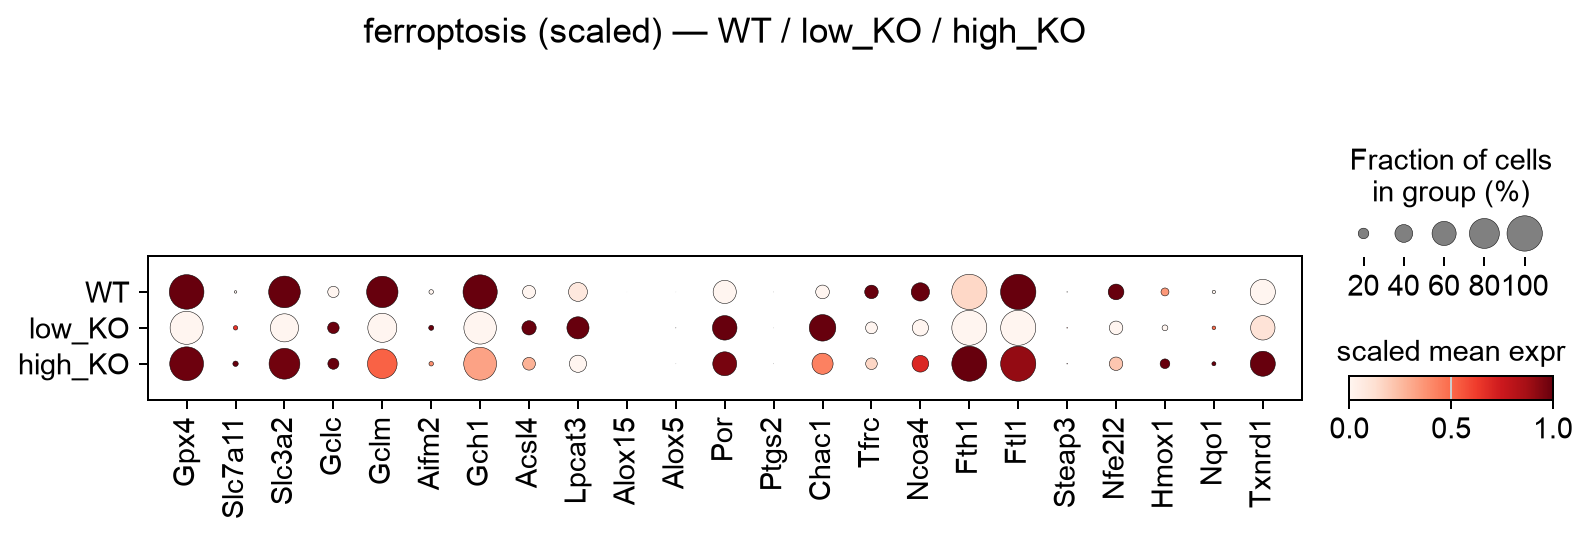

In [36]:
import importlib
import matplotlib.pyplot as plt
import scanpy as sc
import bola3_gene_sets
importlib.reload(bola3_gene_sets)          # pick up Ferroptosis/Glutathione after the file swap
from bola3_gene_sets import GENE_SETS

TIER_ORDER = ["WT", "low_KO", "high_KO"]
LAYER = None   # set to "lognorm" if your violins/dotplots ever look centred on zero

# beta lineage only — Cre is beta-restricted, so this is where recombination lives
beta_sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()

GROUPS = {
    "beta_identity":     ["Ins1", "Ins2", "Nkx6-1", "Pdx1", "Mafa", "Ucn3",
                          "Slc2a2", "G6pc2", "Iapp", "Aldh1a3"],
    "iron_homeostasis":  GENE_SETS["Iron_homeostasis"],
    "glutathione":       GENE_SETS["Glutathione_metabolism"],
    "ferroptosis":       GENE_SETS["Ferroptosis"],
}

def tier_dotplot(genes, name, title, scale=False):
    g = [x for x in genes if x in adata.var_names]
    sc.pl.dotplot(
        beta_sub, g, groupby="recomb_tier", layer=LAYER,
        categories_order=TIER_ORDER, cmap="Reds",
        standard_scale="var" if scale else None,
        colorbar_title="scaled mean expr" if scale else "mean expr",
        title=title, show=False,
    )
    tag = "scaled" if scale else "raw"
    plt.savefig(cfg.FIG_DIR / f"03b_dotplot_{name}_{tag}_tiers.png", dpi=300, bbox_inches="tight")
    plt.show()

for name, genes in GROUPS.items():
    pretty = name.replace("_", " ")
    tier_dotplot(genes, name, f"{pretty} — WT / low_KO / high_KO", scale=False)
    tier_dotplot(genes, name, f"{pretty} (scaled) — WT / low_KO / high_KO", scale=True)

---
### What to carry into notebook 05b

- The per-mouse recombination rates, and whether they track the metabolic
  phenotype across your four KO animals.
- The posterior cutoff you settled on, and how many cells it yields per sample.
- Where escapers sit between WT and recombined. This determines which of the
  four contrasts in notebook 05b is your primary result.
- Whether alpha cells differ between genotypes. If they do, you have a
  measurable systemic component, and the escaper-vs-recombined contrast becomes
  the only clean read on the cell-autonomous effect.